<a href="https://colab.research.google.com/github/24ai097-sujipriya/deep-learning-assignments/blob/main/dl(cat2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cryptocurrency Price Prediction using LSTM



In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt


df = pd.read_csv('/content/coin_Aave.csv')


df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)


df = df.ffill().bfill()


subset_size = 2000
data_subset = df.tail(subset_size).copy()


scaler = MinMaxScaler(feature_range=(0, 1))
scaled_close = scaler.fit_transform(data_subset[['Close']].values)

print(f"Original dataset shape: {df.shape}")
print(f"Subset dataset shape: {data_subset.shape}")

Original dataset shape: (275, 10)
Subset dataset shape: (275, 10)


In [17]:
def create_sequences(data, window_size=7):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:(i + window_size)])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

WINDOW_SIZE = 7
X, y = create_sequences(scaled_close, WINDOW_SIZE)
print(f"Input shape (X): {X.shape} (samples, time steps, features)")
print(f"Target shape (y): {y.shape} (samples, targets)")

Input shape (X): (268, 7, 1) (samples, time steps, features)
Target shape (y): (268, 1) (samples, targets)


In [18]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

def build_lstm_model(input_shape):
    model = Sequential([
        LSTM(50, return_sequences=True, input_shape=input_shape),
        Dropout(0.2),
        LSTM(50, return_sequences=False),
        Dropout(0.2),
        Dense(25),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

model = build_lstm_model((WINDOW_SIZE, 1))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 7, 50)          │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 7, 50)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

## Sequential Model Selection & LSTM Architecture

### Why LSTM was Selected
For predicting the next day's closing price of Aave, a **Long Short-Term Memory (LSTM)** network is selected over standard recurrent neural networks (RNNs) and standard feedforward neural networks due to the following reasons:
* **Mitigation of Gradient Issues**: Traditional RNNs suffer from vanishing and exploding gradients when learning dependencies over multiple time steps. LSTMs utilize specialized gating mechanisms that maintain stable gradients, allowing the network to effectively learn from the entire 7-day sliding window.
* **Capture of Temporal Dynamics**: Cryptocurrency markets exhibit strong sequential patterns, dependencies, and momentum. LSTMs are explicitly designed to capture these non-linear temporal relationships and long-term sequential dependencies.

### Core Architecture of an LSTM Cell
An LSTM cell maintains an internal **Cell State ($C_t$)**, which acts as a memory conveyor belt running through the sequence, and a **Hidden State ($h_t$)**, which carries short-term context. The cell regulates information flow through three primary mathematical gates:

1. **Forget Gate ($f_t$)**: Decides which information from the previous cell state should be discarded using a sigmoid neural layer:
   $$f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$$
2. **Input Gate ($i_t$) & Candidate State ($\tilde{C}_t$)**: Determines which new market signals to store in the cell state:
   $$i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$$
   $$\tilde{C}_t = \tanh(W_c \cdot [h_{t-1}, x_t] + b_c)$$
3. **Cell State Update ($C_t$)**: Updates the memory by combining the filtered previous memory and the scaled candidate values:
   $$C_t = f_t * C_{t-1} + i_t * \tilde{C}_t$$
4. **Output Gate ($o_t$) & Hidden State ($h_t$)**: Selects the output prediction for the next timestep based on the updated cell state:
   $$o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$$
   $$h_t = o_t * \tanh(C_t)$$

## Visualizing the LSTM Cell Architecture

Below is a simplified structural diagram of an LSTM cell at time step $t$. It illustrates how the cell state ($C_{t-1} \rightarrow C_t$) acts as a main pathway (conveyor belt) regulated by the three internal gates (Forget, Input, and Output gates):

```text
             Cell State (Long-term memory)
   C_t-1 ------------------[x]--------(+)------------------> C_t
                            ^          ^
                            |          | (Store new info)
                     Forget |          | Candidate: ~C_t
                     Gate   |         [*]
                     [f_t]  |          ^
                       ^    |          | Input Gate [i_t]
                       |    |          |
                       +----+----------+-----------
                       |                          |
                       |                          v
                       |                     tanh(C_t)
                       |                          |
                       |                          v
  [h_t-1, x_t] --------+------------------------>[*]-------> h_t (Hidden State / Output)
                                            Output Gate
                                               [o_t]
```

### Brief Summary of Gate Functions:
* **Forget Gate ($f_t$):** Controls how much of the past memory ($C_{t-1}$) to keep (multiplication `[x]` block).
* **Input Gate ($i_t$):** Determines which newly computed candidate information ($\tilde{C}_t$) to write to the cell state (addition `(+)` block).
* **Output Gate ($o_t$):** Filters the updated cell state through a $\tanh$ activation to produce the next hidden state ($h_t$), which acts as the short-term context and output prediction.

In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

split_idx = int(len(X) * 0.8)

X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

history = model.fit(
    X_train, y_train,
    epochs=25,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

predictions_scaled = model.predict(X_test)

predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test)

mae = mean_absolute_error(y_test_actual, predictions)
rmse = np.sqrt(mean_squared_error(y_test_actual, predictions))

print(f"\nEvaluation Metrics on Test Set:")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

Epoch 1/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 138ms/step - loss: 0.1086 - val_loss: 0.0250
Epoch 2/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0253 - val_loss: 0.0374
Epoch 3/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0197 - val_loss: 0.0115
Epoch 4/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0142 - val_loss: 0.0131
Epoch 5/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0088 - val_loss: 0.0128
Epoch 6/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0062 - val_loss: 0.0142
Epoch 7/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0055 - val_loss: 0.0110
Epoch 8/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0067 - val_loss: 0.0143
Epoch 9/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0062 - val_loss: 0.0126
Epoch 10/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0061 - val_loss: 0.0111
Epoch 11/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0066 - val_loss: 0.0116
Epoch 12/25
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0059 - val_loss: 0.0108


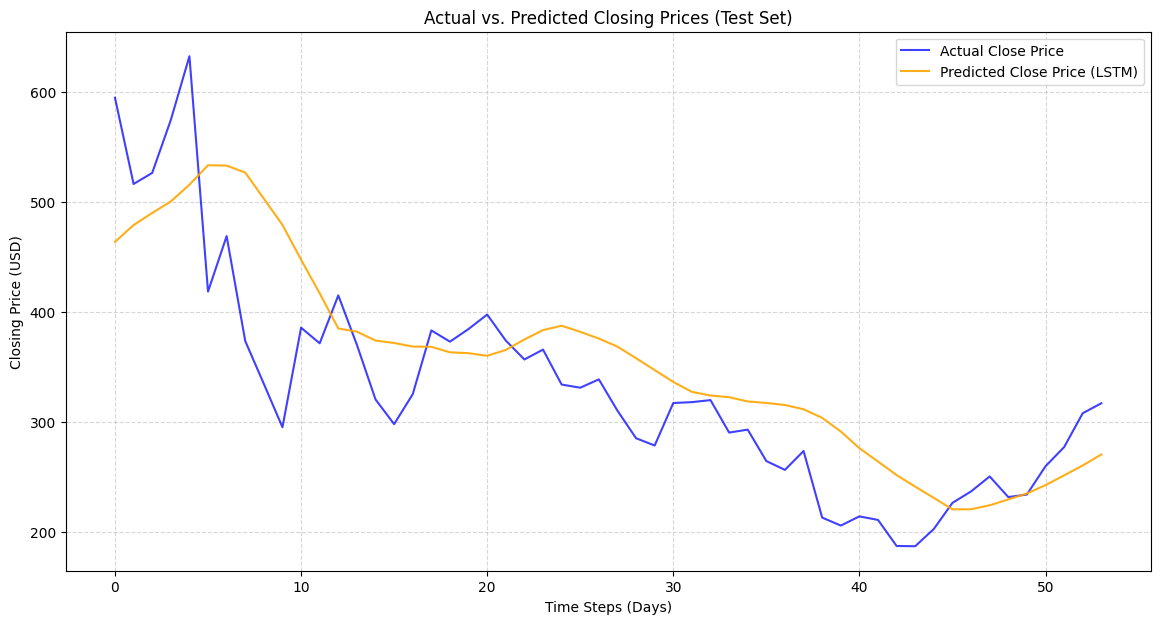

In [20]:

plt.figure(figsize=(14, 7))
plt.plot(y_test_actual, label='Actual Close Price', color='blue', alpha=0.75)
plt.plot(predictions, label='Predicted Close Price (LSTM)', color='orange', alpha=0.9)
plt.title('Actual vs. Predicted Closing Prices (Test Set)')
plt.xlabel('Time Steps (Days)')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Quick Guide: How to Create a GitHub Repository for Your Notebook

If you do not have a GitHub repository yet, follow these quick steps to set one up and upload your `dl(cat2).ipynb` notebook:

### Step 1: Create a GitHub Account and Repository
1. Go to [github.com](https://github.com/) and log in (or sign up if you don't have an account).
2. Click the **"+"** icon in the top-right corner and select **New repository**.
3. Name your repository (for example: `deep-learning-assignments`).
4. Select **Public** (so Google Colab can easily read it without needing credentials).
5. Check the box to **Add a README file** (this initializes the repository main branch).
6. Click **Create repository**.

### Step 2: Save Your Notebook directly from Colab to GitHub
1. Inside this Google Colab tab, click **File** in the top menu.
2. Select **Save a copy in GitHub**.
3. A prompt will request access to your GitHub account. Authorize it.
4. Select your newly created **Repository** and **Branch** (usually `main`).
5. Set the file path to `dl(cat2).ipynb`.
6. Click **OK**.

### Step 3: Accessing Your Notebook Later
Once saved, you can open and run your notebook instantly from any browser using this direct link format:
`https://colab.research.google.com/github/{YOUR_GITHUB_USERNAME}/{YOUR_REPOSITORY_NAME}/blob/main/dl(cat2).ipynb`